# Example in `R`
We have covered a lot of information by this point in the lesson. Although this may give the impression that binary logistic regression is very complex, we will now see that its application is actually quite simple in practice. This is in part due to the support of many familiar functions within `R`, making this a very simple extension of the normal linear model. 

## The `heartdisease` Dataset
...
We will subset these data to only the `cleveland` site and then define a new binary outcome variable based upon the outcome of an angiograph to indicate either the absence or presence of heart disease.

In [11]:
library('datarium')
suppressMessages(library('effects'))
suppressMessages(library('car'))
suppressMessages(library('emmeans'))

data('heartdisease')

cleveland         <- subset(heartdisease, dataset == "cleveland")
cleveland$disease <- as.integer(cleveland$num > 0)
cleveland$sex     <- as.factor(cleveland$sex)
cleveland$cp      <- as.factor(cleveland$cp)

head(cleveland)

  age sex cp trestbps chol fbs restecg thalach exang oldpeak slope ca thal num   dataset disease
1  63   1  1      145  233   1       2     150     0     2.3     3  0    6   0 cleveland       0
2  67   1  4      160  286   0       2     108     1     1.5     2  3    3   2 cleveland       1
3  67   1  4      120  229   0       2     129     1     2.6     2  2    7   1 cleveland       1
4  37   1  3      130  250   0       0     187     0     3.5     3  0    3   0 cleveland       0
5  41   0  2      130  204   0       2     172     0     1.4     1  0    3   0 cleveland       0
6  56   1  2      120  236   0       0     178     0     0.8     1  0    3   0 cleveland       0

## Fitting the Model

### Model Description
$$
\log\left(\frac{\pi_{i}}{1 - \pi_{i}}\right) = \beta_{0} + \left(\beta_{1} \times \text{age}_{i}\right) + \left(\beta_{2} \times \text{SEX}_{i}\right) + \left(\beta_{3} \times \text{CP1}_{i}\right) + \left(\beta_{4} \times \text{CP2}_{i}\right) + \left(\beta_{5} \times \text{CP3}_{i}\right)
$$

where $\text{age}$ is the continuous variable of age, $\text{SEX}$ is the single dummy variable associated with sex and $\text{CP1}$, $\text{CP2}$ and $\text{CP3}$ are the three dummy variables associated with the chest pain categorisation.

### Specifying the Model in `R`

In [17]:
mod <- glm(disease ~ age + sex + cp, family=binomial(link=logit), data=cleveland)
summary(mod)


Call:
glm(formula = disease ~ age + sex + cp, family = binomial(link = logit), 
    data = cleveland)

Coefficients:
            Estimate Std. Error z value Pr(>|z|)    
(Intercept) -6.07927    1.23557  -4.920 8.65e-07 ***
age          0.06661    0.01767   3.770 0.000163 ***
sex1         1.71946    0.34332   5.008 5.49e-07 ***
cp2         -0.25304    0.61782  -0.410 0.682125    
cp3         -0.10433    0.55593  -0.188 0.851142    
cp4          2.27264    0.53230   4.269 1.96e-05 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

(Dispersion parameter for binomial family taken to be 1)

    Null deviance: 417.98  on 302  degrees of freedom
Residual deviance: 293.87  on 297  degrees of freedom
AIC: 305.87

Number of Fisher Scoring iterations: 5


### Interpreting the Estimates

The intercept is therefore the predicted log-odds of having heart disease if you are female, have chest pains associated with typical angina and are aged 0. Clearly, this is not particularly useful. We could make it more useful by mean-centering `age` so that the intercept represents the *average* age in the sample, but we will leave this to one side as it does not matter particularly. We could convert this to a probability using

In [18]:
beta.0 <- coef(mod)[1]
plogis(beta.0)

(Intercept) 
0.002284608 

but, given how unhelpful the interpretation is, this is of little value, especially as the probability is getting close to 0. 

In [20]:
beta <- coef(mod)[2:6]
exp(beta)

      age      sex1       cp2       cp3       cp4 
1.0688792 5.5814990 0.7764400 0.9009311 9.7050108 

We could also turn these into percentage changes in the odds using

In [21]:
(exp(beta) - 1)*100

       age       sex1        cp2        cp3        cp4 
  6.887922 458.149903 -22.356003  -9.906888 870.501079 

... These changes sound dramatic, but remember that these are changes in the odds-ratio, not probability. If the odds-ratio were 2, that would indicate that the odds of having the disease are twice as high as the odds of not having the disease. This would equate to a percentage of $(2 - 1) \times 100 = 100\%$. A change of around 400% is therefore associated with an odds ratio of 5, because $(5 - 1) \times 100 = 400\%$. In the context of `sex`, this means that the odds of heart disease are around 5 times higher in males compared to females. However, this all depends upon what the odds are to begin with. Remember, 5 times a small number is still a small number.

The `effects` package can be invaluable for helping make sense of these various effects ... 

In [29]:
effs <- effect('sex',mod)
print(effs)


 sex effect
sex
        0         1 
0.1908713 0.5683442 


In [35]:
effs$fit
exp(effs$fit)

       [,1]
1 0.2358973
2 1.3166606

In females this is an odds of $\frac{0.24}{1} \approx \frac{1}{4}$, indicating only 1 case of heart disease for every 4 cases of non-heart disease. By comparison, males have an odds of $1.32$, indicating a little over 1 instance of heart disease for every instance of no heart disease. This gives rougly $\frac{1}{5} = 0.2$ probability for females and $\frac{1}{2} = 0.5$ probability for males, which agrees with the precise probabilities reported by `effects`. 

In [36]:
1.31666606/0.2358973

[1] 5.581522

## Model Diagnostics

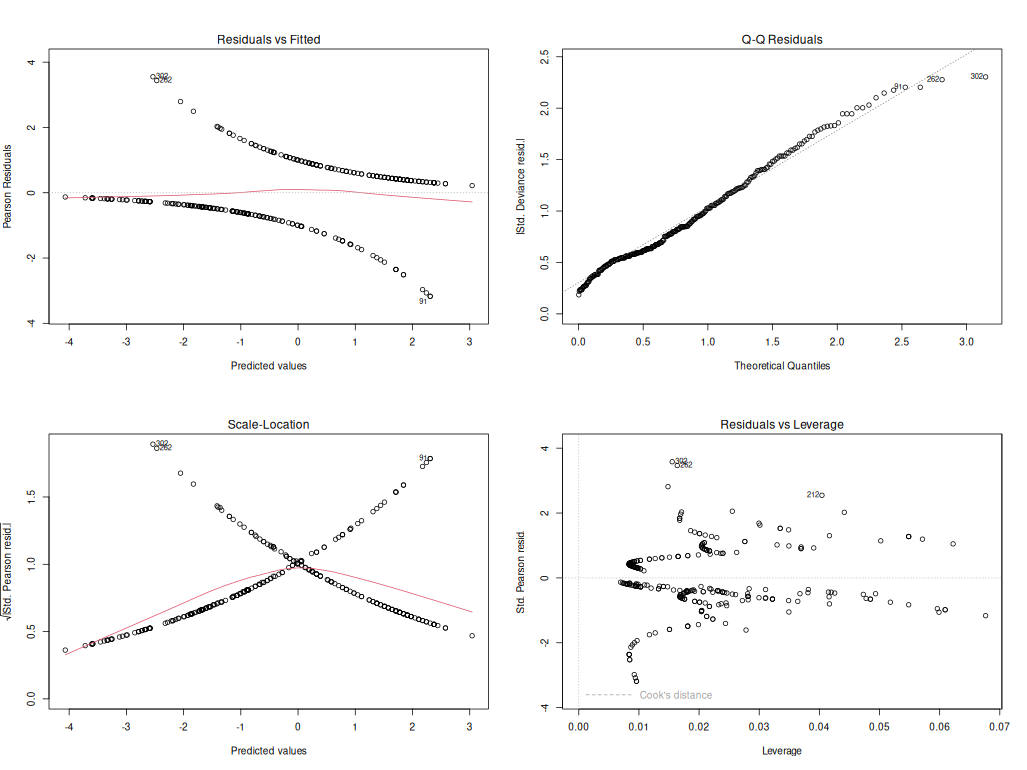

In [3]:
par(mfrow=c(2,2))
plot(mod)
par(mfrow=c(1,1))

### Plotting the Model Fit

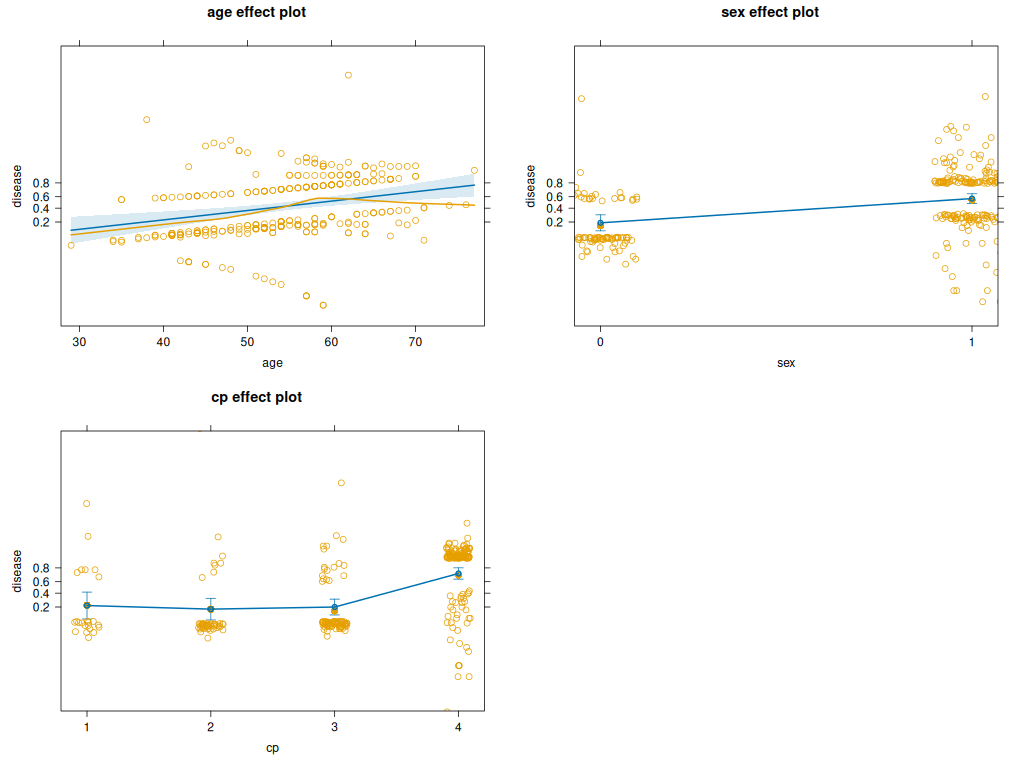

In [4]:
library('effects')
plot(allEffects(mod, partial.residuals=TRUE))

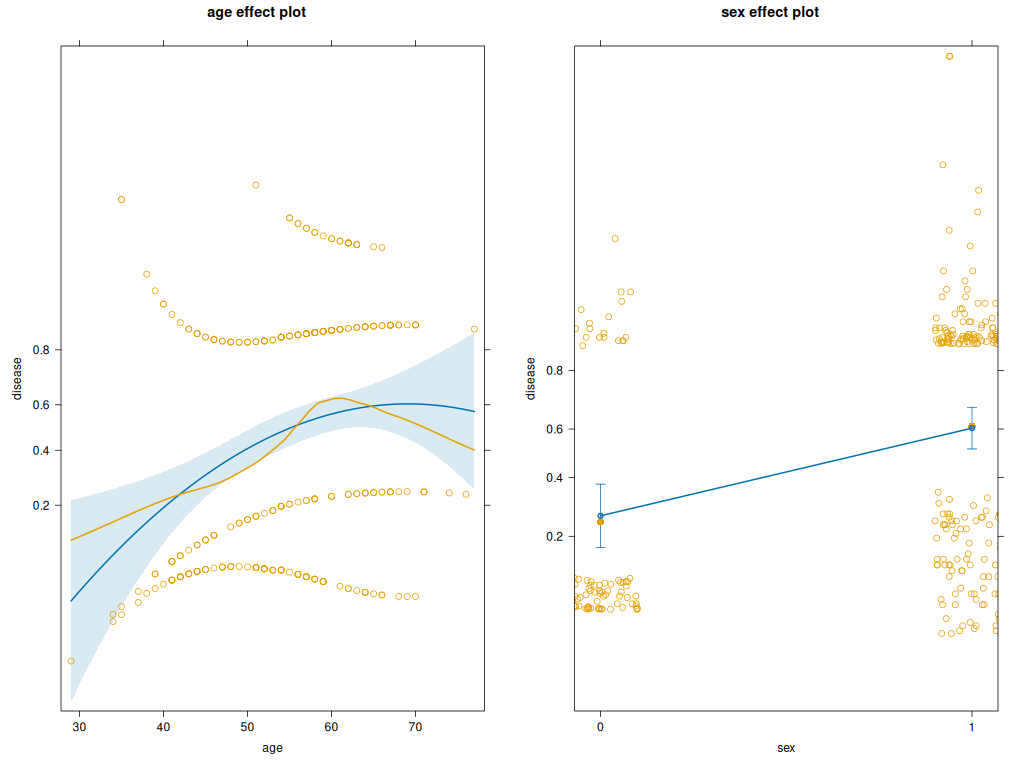

In [5]:
mod.2 <- glm(disease ~ poly(age,2) + sex, family=binomial(link=logit), data=cleveland)
plot(allEffects(mod.2, partial.residuals=TRUE))

#### Options for Scaling Effects Displays

Notice that the `effects` package is smart enough to recognise that this is a logistic regression model and thus has transformed the prediction on to an easier scale. However, there are 3 possibilities here in terms of how this is displayed. These are compared visually and then explained below.


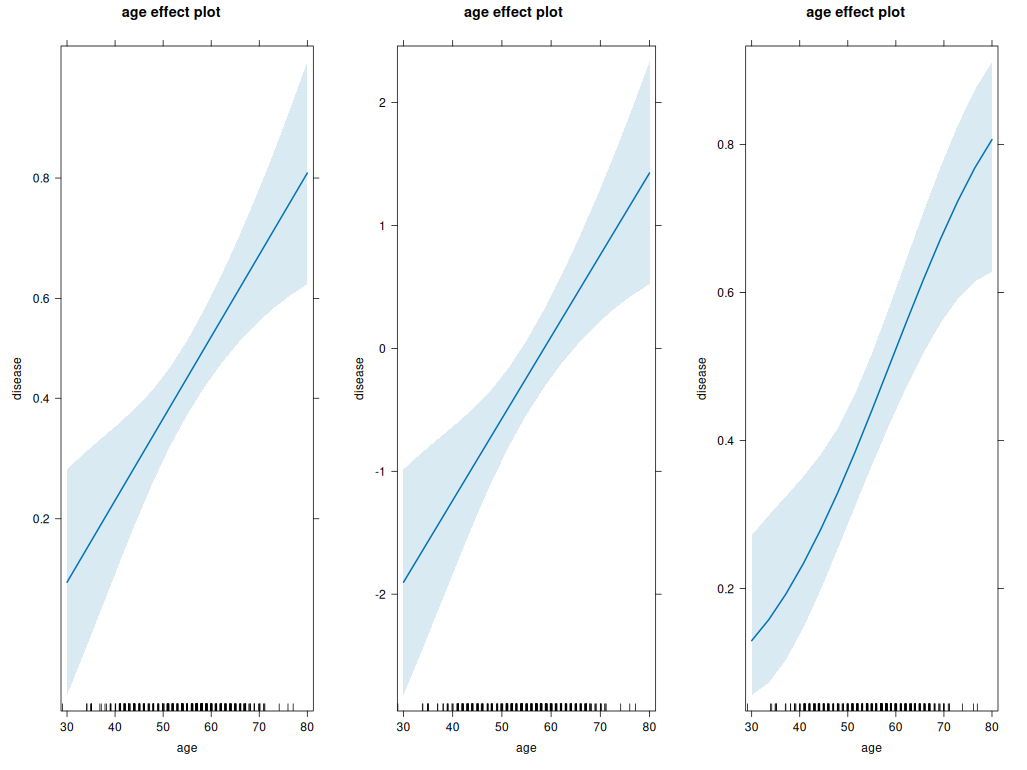

In [6]:
library(gridExtra)

# extract age effect
age.eff <- effect('age',mod)

# compare plots
p1 <- plot(age.eff, axes=list(y=list(type="rescale" ))) # link scale w/prob labels
p2 <- plot(age.eff, axes=list(y=list(type="link"    ))) # link scale
p3 <- plot(age.eff, axes=list(y=list(type="response"))) # probability scale

grid.arrange(p1, p2, p3, ncol=3)

The first plot (*left*) is the default and uses the option `type="rescale"`. This will draw the $y$-axis using the log-odds scale so that the fit is linear. However, to make this easier to interpret, probability labels will be written instead. For instance, a probability of 0.2 is equivalent to a log-odds of −1.386. So the plot places the label "0.2" at the location "-1.386" on the $y$-axis. Notice that the gap between 0.4 and 0.6 is not the same as the gap between 0.6 and 0.8. So the model fit is not linear on the probability scale.

The second plot (*middle*) uses the option `type="link"`, and will do exactly the same as above, but *without* the probability labels. As such, this is a direct plot of the model fit on the scale of the link function, meaning the $y$-axis is given in units of the log-odds.

The final plot (*right*) uses the option `type="response"`, and will draw the model fit on the true probability scale after piping the model through the inverse link function. This means that the S-shaped curved typified by the logit link will be visible on the plot.

In general, `"rescale"` or `"response"` are the most practical, as these present the effects on an interpretable scale in terms of probability. The log-odds scale is not very intuitive and would generally be a poor choice for visualisation. As such, the difference is largely between whether you want to see the sigmoidal curves, or would rather interpret the effects in terms of the straight-line fit.

## Inference on the Effects

### Wald Tests

### Omnibus Tests

In [7]:
Anova(mod)

Analysis of Deviance Table (Type II tests)

Response: disease
    LR Chisq Df Pr(>Chisq)    
age   15.428  1  8.573e-05 ***
sex   28.597  1  8.911e-08 ***
cp    78.434  3  < 2.2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

We can easily demonstrate how these tests are equivalent to model comparisons by computing one of them using explicit model comparisons. For instance, to test the effect of `cp` we can specific a null model that does not contain `cp` and a full model that does contain `cp`.

In [8]:
mod.0 <-  glm(disease ~ age + sex,      family=binomial(link=logit), data=cleveland)
mod.1 <-  glm(disease ~ age + sex + cp, family=binomial(link=logit), data=cleveland)

We can then compare these using the `anova` function

In [9]:
anova(mod.0,mod.1)

Analysis of Deviance Table

Model 1: disease ~ age + sex
Model 2: disease ~ age + sex + cp
  Resid. Df Resid. Dev Df Deviance  Pr(>Chi)    
1       300     372.31                          
2       297     293.87  3   78.434 < 2.2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Notice that the `Df`, `Deviance` and $p$-value are all identical to the table from `Anova`, demonstrating that these results are indeed model comparisons.

### Follow-up Tests

In [10]:
library(emmeans)

## Conclusions